In [2]:
import numpy as np
import  pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN,LSTM,GRU,Dense

In [3]:
from sklearn.preprocessing import MinMaxScaler

In [4]:

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"

df = pd.read_csv(url)

print(df.head())
print(df.columns)
print(df.shape)


     Month  Passengers
0  1949-01         112
1  1949-02         118
2  1949-03         132
3  1949-04         129
4  1949-05         121
Index(['Month', 'Passengers'], dtype='object')
(144, 2)


In [5]:
data=df["Passengers"].values.reshape(-1,1)
print(data.shape)
print(data[:5])

(144, 1)
[[112]
 [118]
 [132]
 [129]
 [121]]


In [6]:
split=int(len(data)*0.8)
train_data=data[:split]
test_data=data[split:]
print("total data:",len(data))
print("test data:",len(test_data))
print("train data:",len(train_data))

total data: 144
test data: 29
train data: 115


In [7]:
scaler=MinMaxScaler(feature_range=(0,1))
train_scaled=scaler.fit_transform(train_data)
test_scaled=scaler.transform(test_data)
print("Training shape:", train_scaled.shape)
print("Testing shape:", test_scaled.shape)
print("First 5 scaled values:")
print(train_scaled[:5])

Training shape: (115, 1)
Testing shape: (29, 1)
First 5 scaled values:
[[0.02067183]
 [0.03617571]
 [0.07235142]
 [0.06459948]
 [0.04392765]]


In [8]:
look_back=10
def create_sequence(series,look_back):
    x,y=[],[]
    for i in range(len(series)-look_back):
        x.append(series[i:i+look_back])
        y.append(series[i+look_back])
    return np.array(x),np.array(y)
x_train,y_train=create_sequence(train_scaled,look_back)
print("x_train shape:",x_train.shape)
print("y_train shape:",y_train.shape)

x_train shape: (105, 10, 1)
y_train shape: (105, 1)


In [9]:
all_scaled=np.concatenate((train_scaled,test_scaled),axis=0)
test_with_history=all_scaled[len(train_scaled)-look_back:]
x_test,y_test=create_sequence(test_with_history,look_back)
print("X_test shape:", x_test.shape)
print("y_test shape:", y_test.shape)


X_test shape: (29, 10, 1)
y_test shape: (29, 1)


In [10]:
def build_model(model_type):
    model=tf.keras.Sequential()
    model.add(tf.keras.Input(shape=(look_back,1)))
    if model_type=="RNN":
        model.add(tf.keras.layers.SimpleRNN(32))
    elif model_type=="LSTM":
        model.add(tf.keras.layers.LSTM(32))
    elif model_type=="GRU":
        model.add(tf.keras.layers.GRU(32))
    model.add(tf.keras.layers.Dense(1))
    model.compile(optimizer="adam",loss="mse")
    return model

In [11]:
models={}
for name in ["RNN","LSTM","GRU"]:
    print("Training",name,"....")
    model=build_model(name)
    model.fit(x_train,y_train,epochs=10,batch_size=16,verbose=1)
    models[name]=model
print("All models trained successfully!")
    

Training RNN ....
Epoch 1/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 0.1380
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0297
Epoch 3/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0270 
Epoch 4/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0141
Epoch 5/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0172
Epoch 6/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0118
Epoch 7/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0121
Epoch 8/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0105
Epoch 9/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0098
Epoch 10/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0090
Training LSTM ....
Epoch 1/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 0.2918
Epoch 2/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.1849
Epoch 3/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.1047
Epoch 4/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0488
Epoch 5/10
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0248
E

In [12]:
from sklearn.metrics import mean_squared_error
actual=scaler.inverse_transform(y_test)
predictions={}
for name,model in models.items():
    pred_scaled=model.predict(x_test,verbose=0)
    pred=scaler.inverse_transform(pred_scaled)
    predictions[name]=pred
    rmse=np.sqrt(mean_squared_error(actual,pred))
    print(name,"RSME",round(rmse,3))

RNN RSME 85.909
LSTM RSME 105.875
GRU RSME 114.814


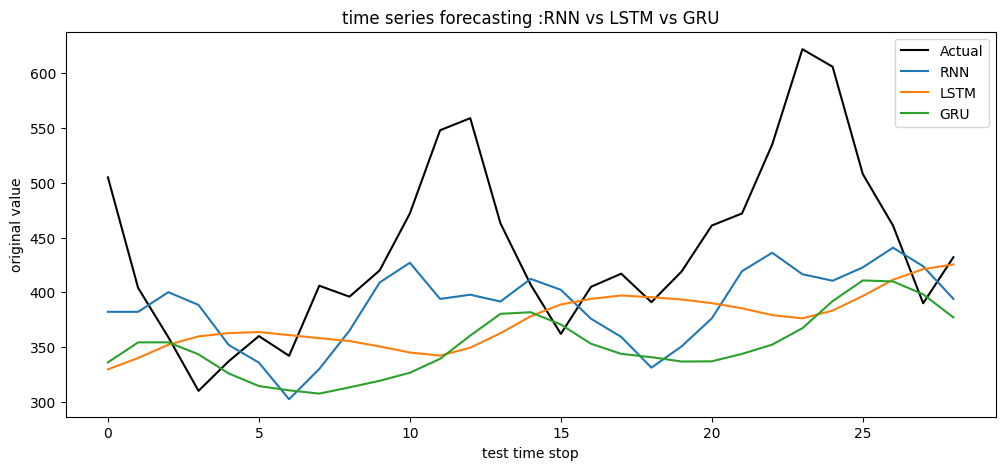

In [13]:
plt.figure(figsize=(12,5))
plt.plot(actual,label="Actual",color="black")
for name,pred in predictions.items():
    plt.plot(pred,label=name)
plt.title("time series forecasting :RNN vs LSTM vs GRU")
plt.xlabel("test time stop")
plt.ylabel("original value")
plt.legend()
plt.show()
